# Vertical Cross-Section Plotting Process

This notebook explains the step-by-step process used in the `70` series scripts to extract data, interpolate it over a depth profile, and plot a vertical cross-section of environmental parameters along a specific transect of stations in Ise-Mikawa Bay.

## Step 1: Map the Transect Stations

First, we visualize where the target stations (00002355 to 00002343) are located geographically. We adhere strictly to the `SIS_mapping_standard` guidelines for the plot setup.

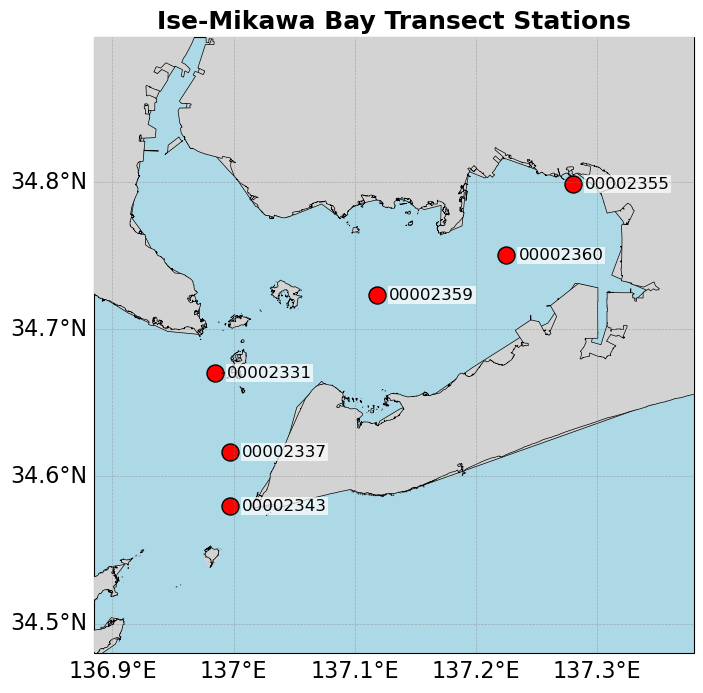

In [3]:
import sys
from pathlib import Path
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Add project root to sys.path
project_root = Path('..').resolve()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from utils.paths import ProjectPaths
from utils.mapping_config import MappingConfig

# Apply global style
plt.style.use(str(ProjectPaths.PROJECT_ROOT / 'project_style.mplstyle'))

# 1. Load Data and filter for Target Stations
df = pd.read_feather(ProjectPaths.MERGED_DATA_FILE)
df['zettaicode'] = df['zettaicode'].astype(str).str.zfill(8)
TARGET_STATIONS = ['00002355', '00002360', '00002359', '00002331', '00002337', '00002343']
stations_df = df[df['zettaicode'].isin(TARGET_STATIONS)].drop_duplicates('zettaicode').copy()

# Ensure we have geometry
stations_gdf = gpd.GeoDataFrame(stations_df, geometry=gpd.points_from_xy(stations_df.longitude, stations_df.latitude), crs="EPSG:4326")

# 2. Base Figure Setup (using dynamic figsize based on Ise Bay extent)
# MappingConfig expects a specific string for region, e.g., 'Ise Bay' or 'Ise-Mikawa Bay'
# We will use the data bounds with 11% proportional buffer
bounds = stations_gdf.total_bounds # [minx, miny, maxx, maxy]
extent = [bounds[0]-0.1, bounds[2]+0.1, bounds[1]-0.1, bounds[3]+0.1]

fig_width, fig_height = MappingConfig.get_dynamic_figsize(extent, base_width=10)
fig, ax = plt.subplots(figsize=(fig_width, fig_height), subplot_kw={'projection': ccrs.PlateCarree()})

# Ocean background
ax.set_facecolor(MappingConfig.COLOR_OCEAN)

# 3. Custom Coastal Boundaries
# Load Plotting Mask (Landmass Boundary)
land_boundary_file = MappingConfig.get_boundary_file('Ise Bay') # Fallback to standard
land_boundary_path = ProjectPaths.BOUNDARIES_DIR / "SIS_prefecture_boundaries" / land_boundary_file
if not land_boundary_path.exists():
    # fallback to simplified national boundary
    land_boundary_path = ProjectPaths.BOUNDARIES_DIR / "Whole nation administrative boundary" / "N03-20240101_prefecture(simplified0.01).shp"
    
sis_land_boundary = gpd.read_file(land_boundary_path)
if sis_land_boundary.crs != "EPSG:4326":
    sis_land_boundary = sis_land_boundary.to_crs("EPSG:4326")

# Plot standard Cartopy Land and Coastlines underneath
ax.add_feature(cfeature.LAND, facecolor=MappingConfig.COLOR_LAND, zorder=MappingConfig.ZORDER_CARTOPY_LAND)
ax.add_feature(cfeature.COASTLINE, linewidth=0.5, edgecolor='black', zorder=MappingConfig.ZORDER_CARTOPY_COASTLINE)

# Plot high-resolution land masses on top
sis_land_boundary.plot(
    ax=ax,
    facecolor=MappingConfig.COLOR_LAND,
    edgecolor=MappingConfig.COLOR_LAND_EDGE,
    linewidth=MappingConfig.LINEWIDTH_LAND,
    transform=ccrs.PlateCarree(),
    zorder=MappingConfig.ZORDER_LAND
)

# 4. Gridlines
gl = ax.gridlines(draw_labels=True, linestyle=MappingConfig.GRID_LINESTYLE, 
                  color=MappingConfig.GRID_COLOR, alpha=MappingConfig.GRID_ALPHA, 
                  linewidth=MappingConfig.GRID_LINEWIDTH, zorder=MappingConfig.ZORDER_GRIDLINES)

# Set zorder on the main gridliner object
gl.set_zorder(MappingConfig.ZORDER_GRIDLINES)

# Remove or comment out the legacy artist z-order assignments:
# gl.xlines.set_zorder(MappingConfig.ZORDER_GRIDLINES)
# gl.ylines.set_zorder(MappingConfig.ZORDER_GRIDLINES)

gl.top_labels = False
gl.right_labels = False


# 5. Plot the stations
stations_gdf.plot(ax=ax, markersize=150, color='red', edgecolor='black', 
                  transform=ccrs.PlateCarree(), zorder=MappingConfig.ZORDER_PREDICTED)

# Add text labels for stations
for x, y, label in zip(stations_gdf.geometry.x, stations_gdf.geometry.y, stations_gdf['zettaicode']):
    ax.text(x + 0.01, y, label, fontsize=12, transform=ccrs.PlateCarree(), 
            zorder=MappingConfig.ZORDER_OBSERVATIONS, ha='left', va='center',
            bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=1))

ax.set_extent(extent, crs=ccrs.PlateCarree())
ax.set_title('Ise-Mikawa Bay Transect Stations')
plt.show()


## Step 2: Preparing Data and Distances

We filter the data for a specific season (e.g. 1999 Summer) and parameter (e.g. Water Temperature). We calculate the cumulative geographic distance between stations to serve as the true continuous spatial X-axis.

In [5]:
import math
import numpy as np

def haversine(lat1, lon1, lat2, lon2):
    R = 6371.0 # Earth radius in km
    dlat = math.radians(lat2 - lat1)
    dlon = math.radians(lon2 - lon1)
    a = math.sin(dlat / 2)**2 + math.cos(math.radians(lat1)) * math.cos(math.radians(lat2)) * math.sin(dlon / 2)**2
    c = 2 * math.atan2(math.sqrt(a), math.sqrt(1 - a))
    return R * c

# Pre-calculate distances and depths
station_info = {}
for st in TARGET_STATIONS:
    st_data = df[df['zettaicode'] == st]
    if not st_data.empty:
        lat = pd.to_numeric(st_data['latitude'], errors='coerce').mean()
        lon = pd.to_numeric(st_data['longitude'], errors='coerce').mean()
        depth = pd.to_numeric(st_data['depth'], errors='coerce').max()
        station_info[st] = {'lat': lat, 'lon': lon, 'depth': depth}

cumulative_dist = 0.0
for i, st in enumerate(TARGET_STATIONS):
    if i == 0:
        station_info[st]['dist'] = 0.0
    else:
        prev_st = TARGET_STATIONS[i-1]
        dist = haversine(station_info[prev_st]['lat'], station_info[prev_st]['lon'], 
                         station_info[st]['lat'], station_info[st]['lon'])
        cumulative_dist += dist
        station_info[st]['dist'] = cumulative_dist

# Filter subset
subset = df[(df['surveyyear'] == 1999) & (df['season'] == 'Summer')].copy()

# ---> FIX: Ensure we only keep the TARGET_STATIONS in this subset
subset = subset[subset['zettaicode'].isin(TARGET_STATIONS)]

subset = subset[subset['saisuipoin'].isin([1, 2])]
subset['saisuidept'] = pd.to_numeric(subset['saisuidept'], errors='coerce')
subset['wtemp'] = pd.to_numeric(subset['wtemp'], errors='coerce')
subset = subset.dropna(subset=['saisuidept', 'wtemp', 'zettaicode'])
subset['distance'] = subset['zettaicode'].map(lambda x: station_info[x]['dist'])

# Extract coordinates for interpolation
x = subset['distance'].values
y = subset['saisuidept'].values
z = subset['wtemp'].values

print(f"Extracted {len(x)} data points for Summer 1999 Water Temperature.")


Extracted 12 data points for Summer 1999 Water Temperature.


## Step 3: Interpolation (griddata)

We construct a dense rectangular meshgrid spanning the distance and max depth. `scipy.interpolate.griddata` calculates Delaunay Triangulation to linearly interpolate values between our sparse surface and bottom data points.

In [8]:
from scipy.interpolate import griddata

max_dist = station_info[TARGET_STATIONS[-1]]['dist']
max_depth_all = max([info['depth'] for info in station_info.values() if pd.notna(info['depth'])])

# Create 100x100 resolution grid
grid_x, grid_y = np.mgrid[0:max_dist:100j, 0:max_depth_all:100j]

# Linearly interpolate z values onto the grid based on the given x, y anchor points
grid_z = griddata((x, y), z, (grid_x, grid_y), method='linear')


## Step 4: Final Plot Rendering

We assemble the final figure by layering the interpolated contours, distinct contour lines, the bathymetry bottom fill, and the original sampling dots.

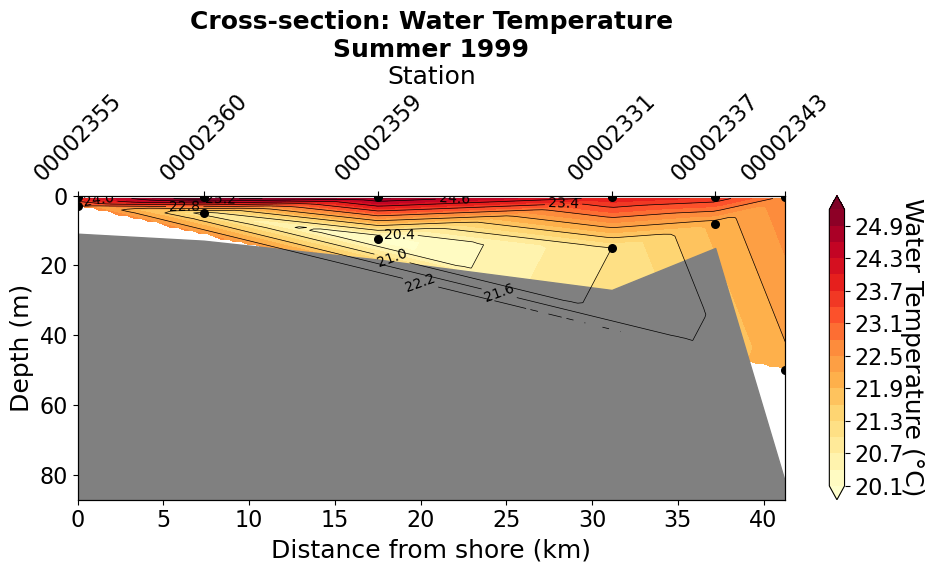

In [9]:
fig, ax = plt.subplots(figsize=(10, 6))

# 1. Filled contour plot
contour = ax.contourf(grid_x, grid_y, grid_z, levels=20, cmap='YlOrRd', extend='both')

# 2. Contour lines and labels
contour_lines = ax.contour(grid_x, grid_y, grid_z, levels=10, colors='k', linewidths=0.5)
ax.clabel(contour_lines, inline=True, fontsize=10, fmt='%.1f')

# Colorbar
cbar = fig.colorbar(contour, ax=ax)
cbar.set_label('Water Temperature (°C)', rotation=270, labelpad=15)

# 3. Bathymetry Fill
dists = [station_info[st]['dist'] for st in TARGET_STATIONS]
depths = [station_info[st]['depth'] for st in TARGET_STATIONS]
ax.fill_between(dists, depths, max_depth_all + 5, color='gray')

# 4. Station sampling points
ax.scatter(x, y, color='black', s=30, label='Sampling Points')

ax.set_ylim(max_depth_all + 5, 0)
ax.set_xlim(0, max_dist)
ax.set_xlabel('Distance from shore (km)')
ax.set_ylabel('Depth (m)')
ax.set_title('Cross-section: Water Temperature\nSummer 1999')

# Top axis for station names
ax2 = ax.twiny()
ax2.set_xlim(ax.get_xlim())
ax2.set_xticks(dists)
ax2.set_xticklabels(TARGET_STATIONS, rotation=45)
ax2.set_xlabel('Station')

plt.tight_layout()
plt.show()
